CATHERINE JOSEPH LWEHUMBIZA
240242457000
BENG24COE_3

TASK 4.1

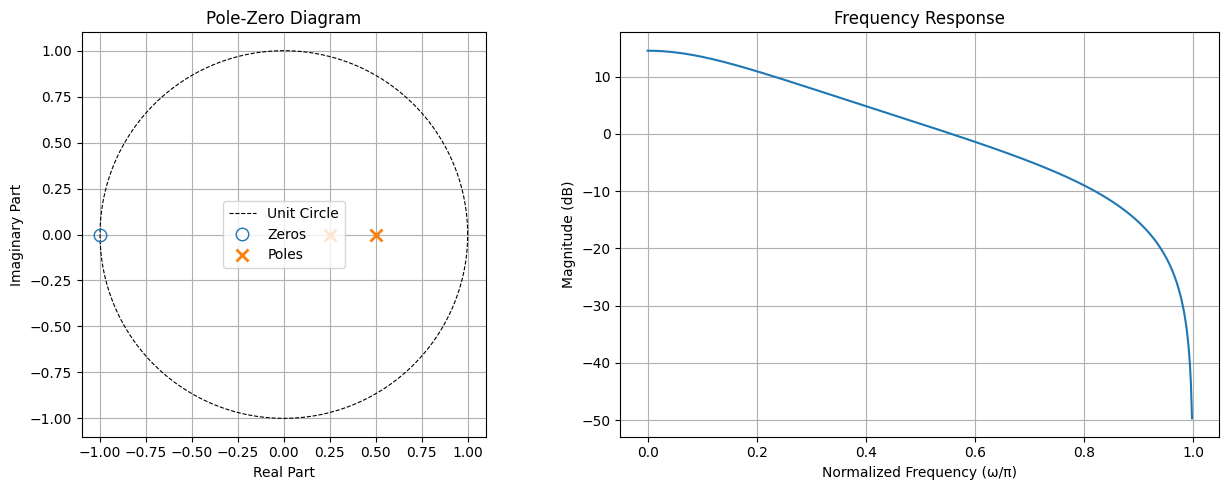

Zeros: [-1.]
Poles: [0.5  0.25]
Is the system stable? True
Pole magnitudes: [0.5  0.25]


In [1]:


import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Step 1: Define the zplane function
def zplane(b, a, ax=None):

    z, p, k = signal.tf2zpk(b, a)

    ax = ax or plt.gca()

    # Draw the unit circle
    th = np.linspace(0, 2*np.pi, 400)

    ax.plot(np.cos(th), np.sin(th),
            "k--", linewidth=0.8, label="Unit Circle")

    # Plot zeros
    ax.plot(z.real, z.imag, "o",
            markerfacecolor="none",
            markersize=9, label="Zeros")

    # Plot poles
    ax.plot(p.real, p.imag, "x",
            markersize=9, markeredgewidth=2,
            label="Poles")

    ax.set_aspect("equal")
    ax.legend()
    ax.set_xlabel("Real Part")
    ax.set_ylabel("Imaginary Part")
    ax.set_title("Pole-Zero Diagram")
    ax.grid(True)

    return z, p


# Step 2: Define system coefficients
b = [1, 1]
a = [1, -0.75, 0.125]

# Step 3: Create two plots
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(13, 5)
)

# Step 4: Plot poles and zeros
z, p = zplane(b, a, ax1)

# Step 5: Calculate frequency response
w, H = signal.freqz(b, a, worN=512)

ax2.plot(w/np.pi, 20*np.log10(np.maximum(np.abs(H), 1e-10)))

ax2.set_title("Frequency Response")
ax2.set_xlabel("Normalized Frequency (ω/π)")
ax2.set_ylabel("Magnitude (dB)")
ax2.grid(True)

plt.tight_layout()
plt.show()

# Step 6: Check stability
stable = np.all(np.abs(p) < 1)

print("Zeros:", z)
print("Poles:", p)
print("Is the system stable?", stable)
print("Pole magnitudes:", np.abs(p))


TASK 4.2

Residues: [-1.  2.]
Poles: [0.25 0.5 ]
Direct term: []

Inverse Z-transform result:
[1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]

Lfilter result:
[1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]

Do both methods match?
True


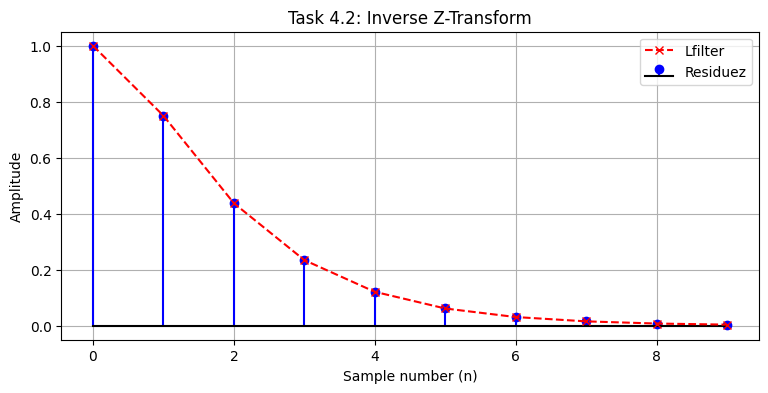

In [1]:

import numpy as np
from scipy import signal
import matplotlib.pyplot as plt

# Define the transfer function
b = [1]
a = [1, -0.75, 0.125]

# Calculate inverse Z-transform using residuez
r, p, k = signal.residuez(b, a)

print("Residues:", r)
print("Poles:", p)
print("Direct term:", k)

# Generate sample numbers
n = np.arange(10)

# Calculate impulse response using partial fractions
x_pf = sum(ri * pi**n for ri, pi in zip(r, p)).real

# Generate impulse signal
impulse = np.zeros(10)
impulse[0] = 1

# Calculate impulse response using lfilter
x_lf = signal.lfilter(b, a, impulse)

# Display both results
print("\nInverse Z-transform result:")
print(x_pf)

print("\nLfilter result:")
print(x_lf)

# Compare the two methods
print("\nDo both methods match?")
print(np.allclose(x_pf, x_lf))

# Plot the results
plt.figure(figsize=(9, 4))

plt.stem(n, x_pf, linefmt='b-', markerfmt='bo',
         basefmt='k-', label='Residuez')

plt.plot(n, x_lf, 'r--', marker='x',
         label='Lfilter')

plt.xlabel("Sample number (n)")
plt.ylabel("Amplitude")
plt.title("Task 4.2: Inverse Z-Transform")
plt.legend()
plt.grid()
plt.show()


TASK 4.3

Radius: 0.5
Pole magnitudes: [0.5 0.5]
System is STABLE
---------------------------
Radius: 0.8
Pole magnitudes: [0.8 0.8]
System is STABLE
---------------------------
Radius: 0.95
Pole magnitudes: [0.95 0.95]
System is STABLE
---------------------------
Radius: 1.0
Pole magnitudes: [1. 1.]
System is MARGINALLY STABLE (not BIBO stable)
---------------------------
Radius: 1.05
Pole magnitudes: [1.05 1.05]
System is UNSTABLE
---------------------------


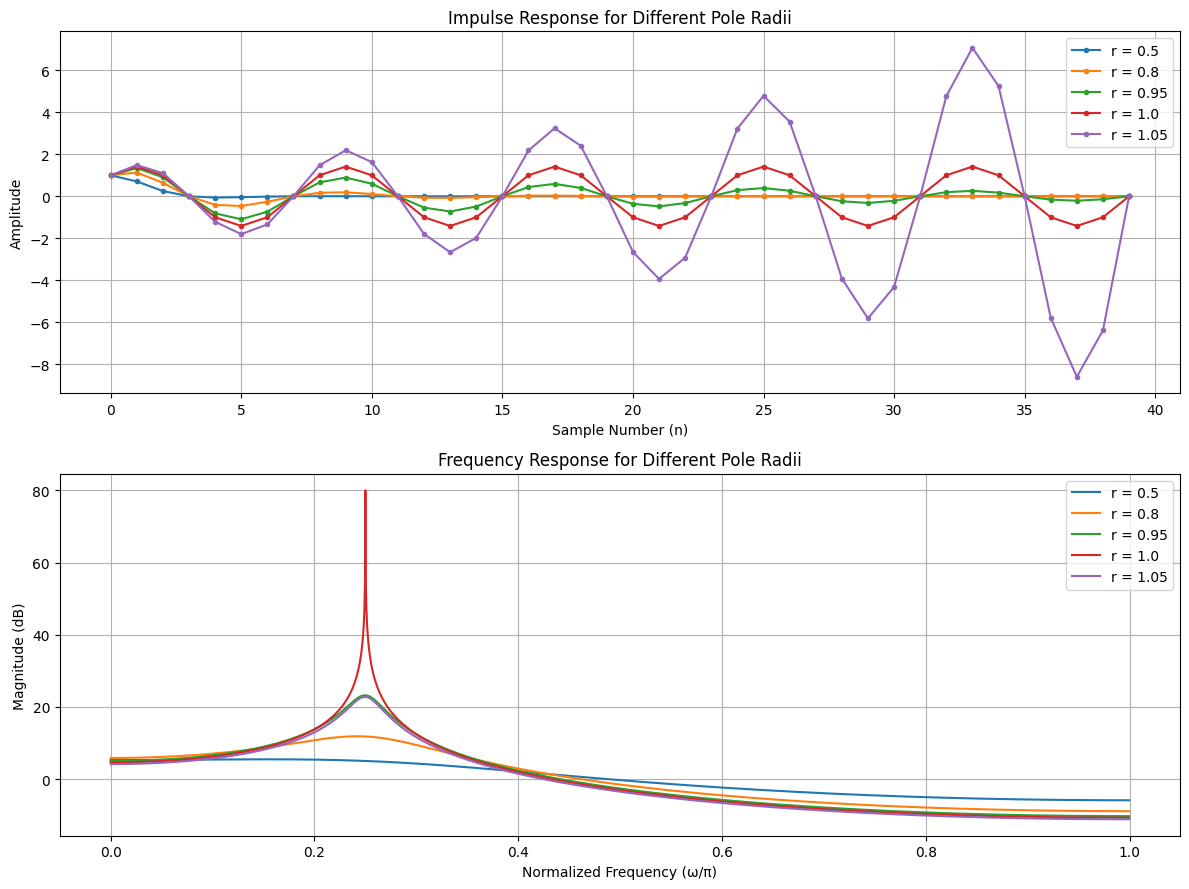

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Pole radius values
r_values = [0.5, 0.8, 0.95, 1.0, 1.05]

# Angle of the complex pole pair
theta = np.pi / 4

# Number of impulse response samples
N = 40
n = np.arange(N)

# Frequency response settings
w_points = 2048

# Create two graphs
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9))

for r in r_values:

    # Denominator coefficients
    a = [1, -2*r*np.cos(theta), r**2]

    # Numerator
    b = [1]

    # Generate impulse signal
    impulse = np.zeros(N)
    impulse[0] = 1

    # Calculate impulse response
    h = signal.lfilter(b, a, impulse)

    # Plot impulse response
    ax1.plot(n, h, marker='o', markersize=3, label=f'r = {r}')

    # Calculate frequency response
    w, H = signal.freqz(b, a, worN=w_points)

    # Convert magnitude to decibels
    magnitude_db = 20 * np.log10(np.maximum(np.abs(H), 1e-10))

    # Limit extreme values for clearer plotting
    magnitude_db = np.clip(magnitude_db, -80, 80)

    # Plot frequency response
    ax2.plot(w/np.pi, magnitude_db, label=f'r = {r}')

    # Check stability using pole magnitudes
    poles = np.roots(a)
    stable = np.all(np.abs(poles) < 1)

    print("Radius:", r)
    print("Pole magnitudes:", np.abs(poles))

    if stable:
        print("System is STABLE")
    elif np.isclose(r, 1.0):
        print("System is MARGINALLY STABLE (not BIBO stable)")
    else:
        print("System is UNSTABLE")

    print("---------------------------")

# Labels for impulse response
ax1.set_title("Impulse Response for Different Pole Radii")
ax1.set_xlabel("Sample Number (n)")
ax1.set_ylabel("Amplitude")
ax1.grid(True)
ax1.legend()

# Labels for frequency response
ax2.set_title("Frequency Response for Different Pole Radii")
ax2.set_xlabel("Normalized Frequency (ω/π)")
ax2.set_ylabel("Magnitude (dB)")
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

TASK 4.4

Radius: 0.5
Pole magnitudes: [0.5 0.5]
System is STABLE
---------------------------
Radius: 0.8
Pole magnitudes: [0.8 0.8]
System is STABLE
---------------------------
Radius: 0.95
Pole magnitudes: [0.95 0.95]
System is STABLE
---------------------------
Radius: 1.0
Pole magnitudes: [1. 1.]
System is MARGINALLY STABLE (not BIBO stable)
---------------------------
Radius: 1.05
Pole magnitudes: [1.05 1.05]
System is UNSTABLE
---------------------------


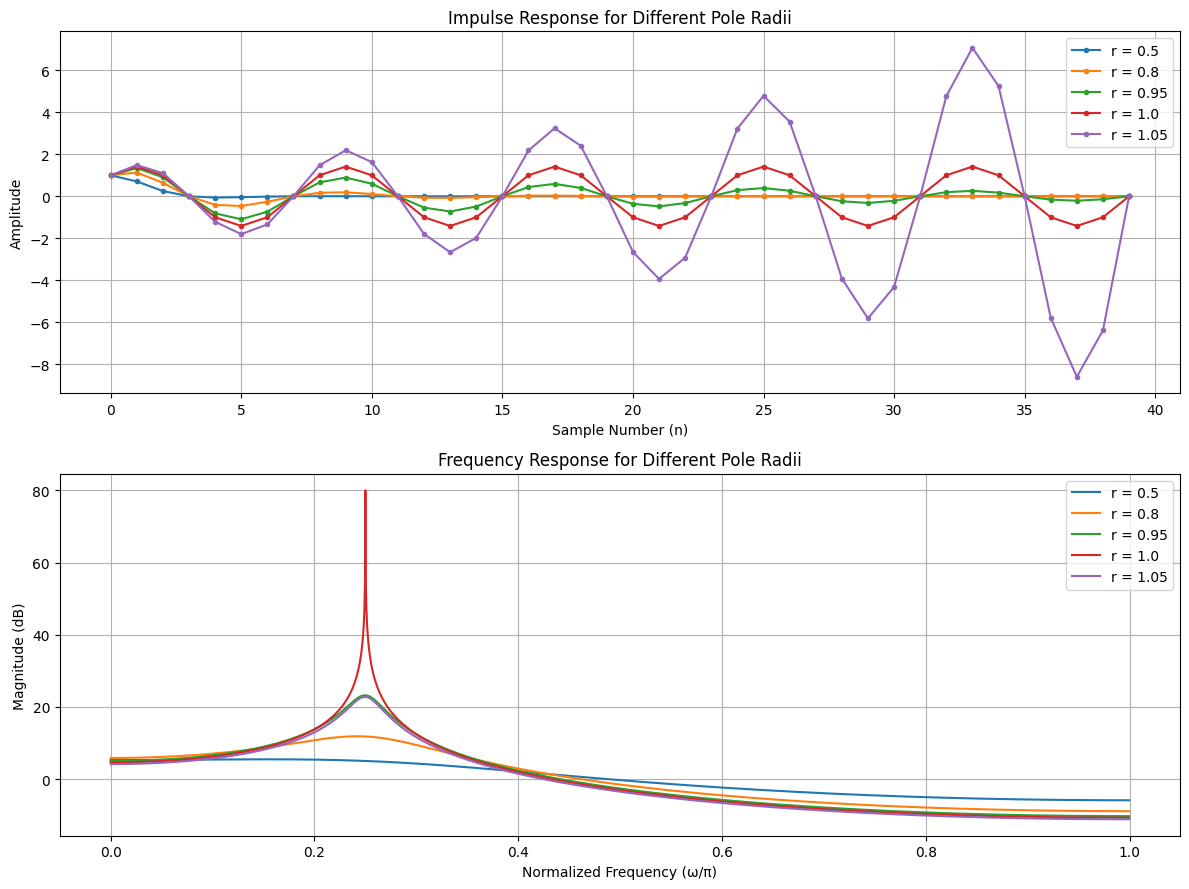

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Pole radius values
r_values = [0.5, 0.8, 0.95, 1.0, 1.05]

# Angle of the complex pole pair
theta = np.pi / 4

# Number of impulse response samples
N = 40
n = np.arange(N)

# Frequency response settings
w_points = 2048

# Create two graphs
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9))

for r in r_values:

    # Denominator coefficients
    a = [1, -2*r*np.cos(theta), r**2]

    # Numerator
    b = [1]

    # Generate impulse signal
    impulse = np.zeros(N)
    impulse[0] = 1

    # Calculate impulse response
    h = signal.lfilter(b, a, impulse)

    # Plot impulse response
    ax1.plot(n, h, marker='o', markersize=3, label=f'r = {r}')

    # Calculate frequency response
    w, H = signal.freqz(b, a, worN=w_points)

    # Convert magnitude to decibels
    magnitude_db = 20 * np.log10(np.maximum(np.abs(H), 1e-10))

    # Limit extreme values for clearer plotting
    magnitude_db = np.clip(magnitude_db, -80, 80)

    # Plot frequency response
    ax2.plot(w/np.pi, magnitude_db, label=f'r = {r}')

    # Check stability using pole magnitudes
    poles = np.roots(a)
    stable = np.all(np.abs(poles) < 1)

    print("Radius:", r)
    print("Pole magnitudes:", np.abs(poles))

    if stable:
        print("System is STABLE")
    elif np.isclose(r, 1.0):
        print("System is MARGINALLY STABLE (not BIBO stable)")
    else:
        print("System is UNSTABLE")

    print("---------------------------")

# Labels for impulse response
ax1.set_title("Impulse Response for Different Pole Radii")
ax1.set_xlabel("Sample Number (n)")
ax1.set_ylabel("Amplitude")
ax1.grid(True)
ax1.legend()

# Labels for frequency response
ax2.set_title("Frequency Response for Different Pole Radii")
ax2.set_xlabel("Normalized Frequency (ω/π)")
ax2.set_ylabel("Magnitude (dB)")
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

TASK 4.5

TASK 4.5: SECOND-ORDER RESONATOR
--------------------------------
Sampling frequency: 8000 Hz
Resonant frequency: 1000 Hz
Pole radius: 0.97
Numerator coefficients: [1, 0, -1]
Denominator coefficients: [1, np.float64(-1.3717871555019023), 0.9409]

Zeros: [-1.  1.]
Poles: [0.68589358+0.68589358j 0.68589358-0.68589358j]
Pole magnitudes: [0.97 0.97]

System Stability: STABLE


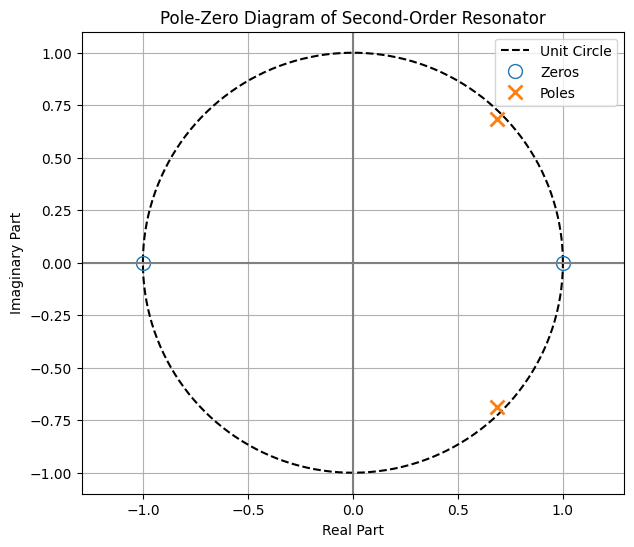

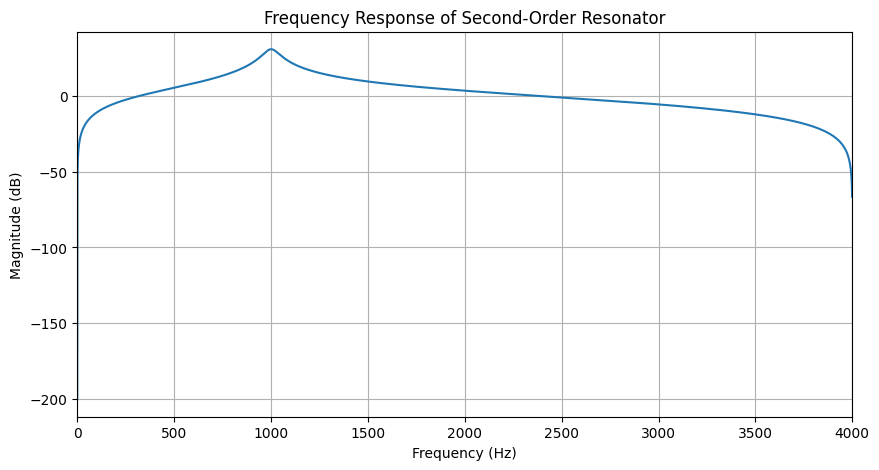


Peak frequency: 1000.9765625 Hz
Expected frequency: 1000 Hz

White noise generated successfully.
Number of samples: 24000
Resonator filter applied successfully.


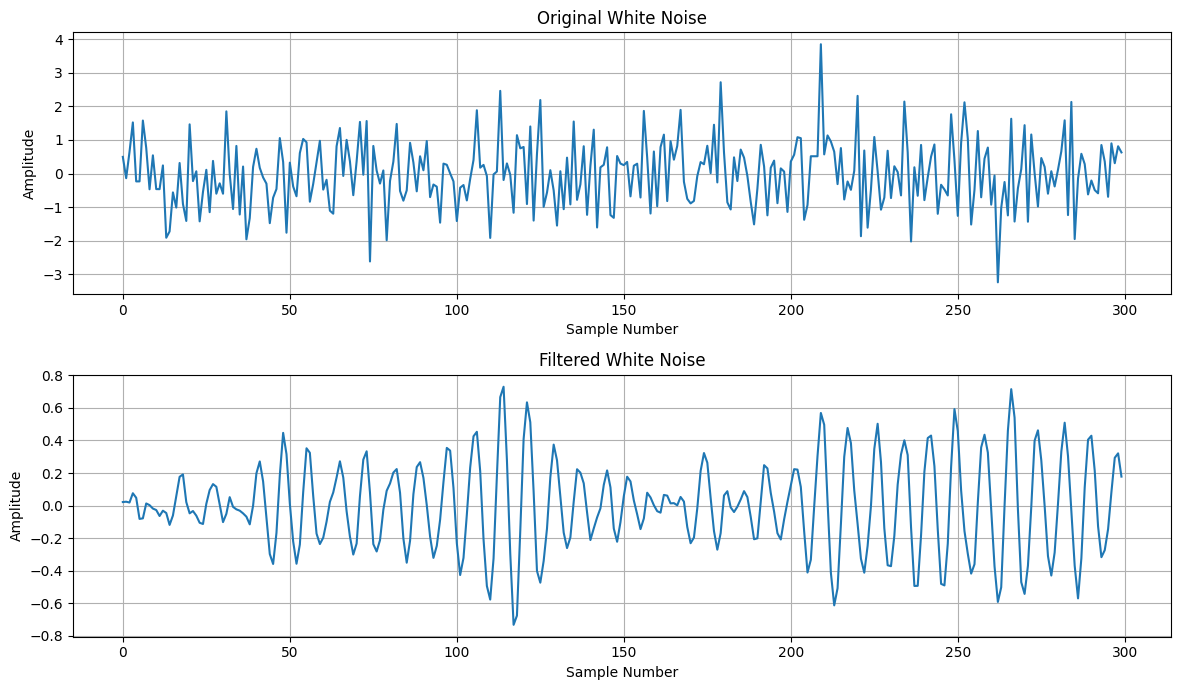

Listen to the filtered white noise below:



========== FINAL RESULTS ==========
Resonator design completed successfully.
Resonant frequency: 1000 Hz
Sampling frequency: 8000 Hz
Pole radius: 0.97
Zeros: [-1.  1.]
Poles: [0.68589358+0.68589358j 0.68589358-0.68589358j]
Stable system: True


In [4]:

# TASK 4.5: DESIGN A SECOND-ORDER RESONATOR

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio, display

# -----------------------------------------
# 1. DESIGN THE SECOND-ORDER RESONATOR
# -----------------------------------------

# Sampling frequency
fs = 8000

# Desired resonant frequency
f0 = 1000

# Pole radius
r = 0.97

# Calculate angular frequency
omega0 = 2 * np.pi * f0 / fs

# Numerator coefficients
# Zeros are placed at z = +1 and z = -1
b = [1, 0, -1]

# Denominator coefficients
# Poles are placed at radius r and angle +/- omega0
a = [
    1,
    -2 * r * np.cos(omega0),
    r**2
]

print("TASK 4.5: SECOND-ORDER RESONATOR")
print("--------------------------------")
print("Sampling frequency:", fs, "Hz")
print("Resonant frequency:", f0, "Hz")
print("Pole radius:", r)
print("Numerator coefficients:", b)
print("Denominator coefficients:", a)

# -----------------------------------------
# 2. CALCULATE POLES AND ZEROS
# -----------------------------------------

zeros, poles, gain = signal.tf2zpk(b, a)

print("\nZeros:", zeros)
print("Poles:", poles)
print("Pole magnitudes:", np.abs(poles))

# Check system stability
if np.all(np.abs(poles) < 1):
    print("\nSystem Stability: STABLE")
else:
    print("\nSystem Stability: UNSTABLE")

# -----------------------------------------
# 3. PLOT POLE-ZERO DIAGRAM
# -----------------------------------------

plt.figure(figsize=(7, 6))

# Unit circle
theta = np.linspace(0, 2*np.pi, 500)

plt.plot(
    np.cos(theta),
    np.sin(theta),
    'k--',
    label="Unit Circle"
)

# Plot zeros
plt.plot(
    zeros.real,
    zeros.imag,
    'o',
    markersize=10,
    markerfacecolor='none',
    label="Zeros"
)

# Plot poles
plt.plot(
    poles.real,
    poles.imag,
    'x',
    markersize=10,
    markeredgewidth=2,
    label="Poles"
)

plt.axhline(0, color='gray')
plt.axvline(0, color='gray')

plt.xlabel("Real Part")
plt.ylabel("Imaginary Part")
plt.title("Pole-Zero Diagram of Second-Order Resonator")

plt.grid(True)
plt.axis("equal")
plt.legend()
plt.show()

# -----------------------------------------
# 4. CALCULATE AND PLOT FREQUENCY RESPONSE
# -----------------------------------------

w, H = signal.freqz(
    b,
    a,
    worN=4096,
    fs=fs
)

# Calculate magnitude in decibels
magnitude_db = 20 * np.log10(
    np.maximum(np.abs(H), 1e-10)
)

plt.figure(figsize=(10, 5))

plt.plot(w, magnitude_db)

plt.title("Frequency Response of Second-Order Resonator")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")

plt.xlim(0, fs/2)
plt.grid(True)
plt.show()

# Find peak frequency
peak_index = np.argmax(np.abs(H))
peak_frequency = w[peak_index]

print("\nPeak frequency:", peak_frequency, "Hz")
print("Expected frequency:", f0, "Hz")

# -----------------------------------------
# 5. GENERATE WHITE NOISE
# -----------------------------------------

np.random.seed(42)

# Generate 3 seconds of white noise
duration = 3

x = np.random.randn(fs * duration)

print("\nWhite noise generated successfully.")
print("Number of samples:", len(x))

# -----------------------------------------
# 6. APPLY RESONATOR FILTER TO WHITE NOISE
# -----------------------------------------

y = signal.lfilter(b, a, x)

# Normalize output signal
y = y / np.max(np.abs(y))

print("Resonator filter applied successfully.")

# -----------------------------------------
# 7. PLOT ORIGINAL AND FILTERED SIGNALS
# -----------------------------------------

plt.figure(figsize=(12, 7))

plt.subplot(2, 1, 1)
plt.plot(x[:300])
plt.title("Original White Noise")
plt.xlabel("Sample Number")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(y[:300])
plt.title("Filtered White Noise")
plt.xlabel("Sample Number")
plt.ylabel("Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()

# -----------------------------------------
# 8. LISTEN TO FILTERED AUDIO
# -----------------------------------------

print("Listen to the filtered white noise below:")

display(Audio(y, rate=fs))

# -----------------------------------------
# 9. FINAL RESULTS
# -----------------------------------------

print("\n========== FINAL RESULTS ==========")
print("Resonator design completed successfully.")
print("Resonant frequency:", f0, "Hz")
print("Sampling frequency:", fs, "Hz")
print("Pole radius:", r)
print("Zeros:", zeros)
print("Poles:", poles)
print("Stable system:", np.all(np.abs(poles) < 1))
print("===================================")


WEEK 4: ANALYSIS QUESTIONS AND ANSWERS
Question 1
Explain how changing the pole radius \(r\) affects the bandwidth of resonance in Task 4.3.

Answer:

The pole radius affects the bandwidth and sharpness of the resonance. When the pole radius is small, the bandwidth is wide and the resonance peak is less sharp. When the pole radius increases towards 1, the bandwidth becomes narrower and the resonance peak becomes sharper. Therefore, a higher pole radius produces a stronger and narrower resonance.
Question 2
What happens to the impulse response when a pole lies exactly on the unit circle?

Answer:

When a pole lies exactly on the unit circle, the impulse response produces continuous oscillations that do not decay with time. The system is not BIBO stable because its impulse response is not absolutely summable. This means the system can produce an unbounded output for some bounded inputs.
Question 3
Why do zeros at \(z=+1\) and \(z=-1\) make the resonator behave like a band-pass filter?

Answer:

The zero at \(z=+1\) blocks the DC component, which corresponds to 0 Hz. The zero at \(z=-1\) blocks the Nyquist frequency, which is half of the sampling frequency. These zeros reduce the response at very low and very high frequencies, while the poles create a peak around the resonant frequency of 1 kHz. Therefore, the resonator behaves like a band-pass filter.
Question 4
Use the stability triangle (handout Example 2.4) to check your answers to Task 4.4 (a)–(c).

Answer:

The stability triangle is used to determine whether a second-order system is stable by checking its denominator coefficients.

For a second-order denominator:
\[
A(z)=1+a_1z^{-1}+a_2z^{-2}
\]

The stability conditions are:
1. \(1+a_1+a_2>0\)
2. \(1-a_1+a_2>0\)
3. \(1-a_2>0\)
System H1:
\[
A_1(z)=1-1.6z^{-1}+0.89z^{-2}
\]

- \(1-1.6+0.89=0.29>0\)
- \(1+1.6+0.89=3.49>0\)
- \(1-0.89=0.11>0\)
Therefore, H1 is stable.

System H2:
\[
A_2(z)=1-2.5z^{-1}+z^{-2}
\]

- \(1-2.5+1=-0.5<0\)
- \(1+2.5+1=4.5>0\)
- \(1-1=0\)
Therefore, H2 is unstable.

System H3:
\[
A_3(z)=1+0.5z^{-1}-0.5z^{-2}
\]

- \(1+0.5-0.5=1>0\)
- \(1-0.5-0.5=0\)
- \(1-(-0.5)=1.5>0\)
Therefore, H3 is not BIBO stable because one pole lies exactly on the unit circle.

Conclusion: H1 is stable, while H2 and H3 are not BIBO stable.

AI USE STATEMENT
AI Use Statement
Artificial Intelligence (AI), specifically ChatGPT, was used as a learning and support tool during the completion of this Digital Signal Processing laboratory assignment.

AI assistance was used to understand DSP concepts, explain the laboratory tasks, develop and correct Python code, troubleshoot programming errors, and interpret graphs and experimental results.

The Google Colab environment was used to execute the Python code and generate the required outputs, including impulse responses, frequency responses, pole-zero diagrams, and filtered audio signals.

I reviewed and tested the provided code and used the results to improve my understanding of digital signal processing concepts.









Is this conversation helpful so far?